# AI Model Profiling Framework — Level 2

This notebook characterizes prompt length, generation length, and batch size, then profiles one Prefill and one cached Decode forward separately. Run top to bottom from the repository root using the project virtual environment. Default model: `sshleifer/tiny-gpt2`.

**Timing boundary:** Prefill times one full-prompt model call plus device synchronization. The Prefill logits supply the first generated token, but argmax token selection is outside the timer. Decode times each of the remaining one-token calls with the KV cache returned by the preceding call. Each step includes post-call synchronization; mask growth and argmax stay outside the timer. The benchmark sums all configured Decode steps. The profiler captures one representative forward per phase after separate warm-up. Model loading, tokenization, and profiler overhead are outside benchmark timing.

The loop uses greedy argmax and always executes the requested number of tokens, including after EOS. `decode_steps_per_s` keeps Level 1's batch-independent call rate; `decode_tokens_per_s` and `end_to_end_tokens_per_s` count tokens across the batch. These are model-forward rates, not user-perceived generation rates.

## Setup and workload selection

Install with `pip install -e .`. The first model load may require Internet. `WORKLOADS` selects one-variable sweeps; it does **not** run the full Cartesian product. Edit lists and constants for larger experiments. `workload_plan.csv` records selected and intentionally skipped dimension combinations, including all labeled sweeps for each selected combination. Each batch contains identical unpadded prompts, so all attention-mask positions are real tokens. Each raw measurement carries `run_id`; results from different runs are not reported as a controlled comparison.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer

from profiling_mvp.level2 import (Workload, benchmark_workloads, build_report,
    choose_device, comparison_issues, make_workload_matrix, metadata, profile_phase, rank_operators, summarize_workloads)

MODEL_NAME = "sshleifer/tiny-gpt2"
DEVICE_REQUESTED = "auto"  # auto, cpu, mps, cuda
SEED = 1234
WARMUP = 1
REPEATS = 3
PROMPT_LENGTHS = [32, 64, 128]  # add 256 when time and memory permit
GENERATION_LENGTHS = [8, 16, 32]  # add 64 when time permits
BATCH_SIZES = [1, 2]
BASE_PROMPT = 64
BASE_NEW_TOKENS = 8
DECODE_CONTEXT_STEPS = 0  # extra cached forwards outside profiler
OUTPUT_DIR = Path("results/notebook_level2")
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
TRACE_DIR = OUTPUT_DIR / "traces" / RUN_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRACE_DIR.mkdir(parents=True, exist_ok=True)

WORKLOADS, workload_plan_df = make_workload_matrix(
    PROMPT_LENGTHS, GENERATION_LENGTHS, BATCH_SIZES, BASE_PROMPT, BASE_NEW_TOKENS
)
PROFILE_WORKLOADS = [Workload("representative", BASE_PROMPT, BASE_NEW_TOKENS, 1)]
workload_plan_df.to_csv(OUTPUT_DIR / "workload_plan.csv", index=False)
DEVICE = choose_device(DEVICE_REQUESTED)
torch.manual_seed(SEED)
if DEVICE == "cuda":
    torch.cuda.manual_seed_all(SEED)
print(f"Device: {DEVICE}; benchmark workloads: {len(WORKLOADS)}; profiler workloads: {len(PROFILE_WORKLOADS)}")
display(pd.DataFrame([vars(w) for w in WORKLOADS]))

Device: mps; benchmark workloads: 8; profiler workloads: 1


,experiment,prompt_tokens,max_new_tokens,batch_size
0,prompt_length,32,8,1
1,prompt_length,64,8,1
2,prompt_length,128,8,1
3,generation_length,64,8,1
4,generation_length,64,16,1
5,generation_length,64,32,1
6,batch_size,64,8,1
7,batch_size,64,8,2


## Load once

The model and tokenizer are reused. Model loading is outside every timed region. A failed download stops here with its original error.

In [2]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(DEVICE).eval()
print("Model loaded:", MODEL_NAME)

Loading weights:   0%|          | 0/29 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: sshleifer/tiny-gpt2
Key                                   | Status     |  | 
--------------------------------------+------------+--+-
transformer.h.{0, 1}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded: sshleifer/tiny-gpt2


## Ordinary benchmark

Each workload gets its own warm-up. Device execution is synchronized around each forward. Every planned measured run has one `raw_runs.csv` row. Invalid configurations are `unsupported`; preparation or warm-up failures make planned runs `skipped`; measured failures are `failed`. Each has a reason. Warm-up runs never enter the table. Only successful runs enter numeric summaries; counts and failure status remain visible. A requested generation length of one has no Decode forward: Decode latency and rates are unavailable. Nonfinite or nonpositive measured durations fail the run. `prompt_tokens_per_s` counts all prompt tokens in the batch divided by Prefill time; Prefill also computes logits, so this is a prompt processing rate rather than tokenization throughput.

In [3]:
raw_df = benchmark_workloads(model, tokenizer, WORKLOADS, DEVICE, WARMUP, REPEATS, run_id=RUN_ID)
assert len(raw_df) == len(WORKLOADS) * REPEATS
summary_df, stability_df = summarize_workloads(raw_df)
raw_df.to_csv(OUTPUT_DIR / "raw_runs.csv", index=False)
summary_df.to_csv(OUTPUT_DIR / "workload_summary.csv", index=False)
stability_df.to_csv(OUTPUT_DIR / "stability_summary.csv", index=False)
display(summary_df[["workload", "status", "runs_ok", "runs_failed", "runs_skipped", "runs_unsupported", "errors",
    "prefill_latency_s_median", "decode_latency_s_median", "decode_tokens_per_s_median"]])

,workload,status,runs_ok,runs_failed,runs_skipped,runs_unsupported,errors,prefill_latency_s_median,decode_latency_s_median,decode_tokens_per_s_median
0,prompt_length_p32_n8_b1,ok,3,0,0,0,None,0.004273,0.017143,408.338839
1,prompt_length_p64_n8_b1,ok,3,0,0,0,None,0.004364,0.015718,445.345798
2,prompt_length_p128_n8_b1,ok,3,0,0,0,None,0.004628,0.015715,445.422453
3,generation_length_p64_n8_b1,ok,3,0,0,0,None,0.004775,0.020447,342.341531
4,generation_length_p64_n16_b1,ok,3,0,0,0,None,0.005916,0.056585,265.089294
5,generation_length_p64_n32_b1,ok,3,0,0,0,None,0.004007,0.062021,499.827359
6,batch_size_p64_n8_b1,ok,3,0,0,0,None,0.004656,0.021572,324.499725
7,batch_size_p64_n8_b2,ok,3,0,0,0,None,0.003989,0.016418,852.724751


## Separate operator profiler pass

Each run uses a unique trace subdirectory. Only paths in `profile_runs.json` belong to the current result set. Each trace contains **one model forward**. Prefill starts from the complete prompt. Decode first builds the KV cache outside the profiler; the profiled forward consumes one cached token. `DECODE_CONTEXT_STEPS` can advance the cache before capture. Thus operator totals describe one forward at that context position, not an entire generation. Profiling overhead never enters `raw_runs.csv`.

CPU activity is available on all supported backends. CUDA activity is requested only on CUDA. On MPS, this notebook records CPU-side PyTorch operator times; they are **not MPS device time**. Missing fields stay null. `operator_summary.csv` retains separate input-shape groups; report and ranking plots combine their self times by operator. PyTorch profiler memory fields describe allocator events, not peak physical memory.

In [4]:
operator_rows = []
profile_runs = []
for workload in PROFILE_WORKLOADS:
    for phase in ("prefill", "decode"):
        rows, info = profile_phase(model, tokenizer, workload, phase, DEVICE,
                                   TRACE_DIR, DECODE_CONTEXT_STEPS)
        operator_rows.extend(rows)
        profile_runs.append(info)
        print(workload.name, phase, info["status"], info.get("error") or info.get("trace"))
operator_df = pd.DataFrame(operator_rows, columns=["workload", "phase", "device", "operator",
    "input_shapes", "cpu_calls", "self_cpu_time_us", "total_cpu_time_us",
    "self_device_time_us", "total_device_time_us", "device_calls",
    "cpu_memory_bytes", "self_cpu_memory_bytes", "device_memory_bytes",
    "self_device_memory_bytes", "trace"])
operator_df.to_csv(OUTPUT_DIR / "operator_summary.csv", index=False)
(OUTPUT_DIR / "profile_runs.json").write_text(json.dumps(profile_runs, indent=2), encoding="utf-8")
if len(operator_df):
    display(operator_df.sort_values("self_cpu_time_us", ascending=False).head(12))

representative_p64_n8_b1 prefill ok results/notebook_level2/traces/20261012T180624440746Z/representative_p64_n8_b1_prefill_mps.json
representative_p64_n8_b1 decode ok results/notebook_level2/traces/20261012T180624440746Z/representative_p64_n8_b1_decode_mps.json


USDT:2026-10-13 01:06:30 71314:6760571 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-13 01:06:30 71314:6760571 SyncActivityProfilerHandler.cpp:46] profiler_stop
USDT:2026-10-13 01:06:30 71314:6760571 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-13 01:06:30 71314:6760571 SyncActivityProfilerHandler.cpp:46] profiler_stop


,workload,phase,device,operator,input_shapes,cpu_calls,self_cpu_time_us,total_cpu_time_us,self_device_time_us,total_device_time_us,device_calls,cpu_memory_bytes,self_cpu_memory_bytes,device_memory_bytes,self_device_memory_bytes,trace
0,representative_p64_n8_b1,prefill,mps,model_forward_prefill,[],1,1211.768,3528.379,None,None,None,0,0,None,None,results/notebook_level2/traces/20261012T180624...
89,representative_p64_n8_b1,decode,mps,model_forward_decode,[],1,891.810,2313.757,None,None,None,0,0,None,None,results/notebook_level2/traces/20261012T180624...
8,representative_p64_n8_b1,prefill,mps,aten::arange,"[[], [], [], [], []]",1,438.449,457.073,None,None,None,0,0,None,None,results/notebook_level2/traces/20261012T180624...
117,representative_p64_n8_b1,decode,mps,aten::_local_scalar_dense,[[]],1,422.255,424.880,None,None,None,0,-1,None,None,results/notebook_level2/traces/20261012T180624...
140,representative_p64_n8_b1,decode,mps,aten::_scaled_dot_product_attention_math_for_mps,"[[1, 2, 1, 1], [1, 2, 65, 1], [1, 2, 65, 1], [...",2,388.752,392.128,None,None,None,0,0,None,None,results/notebook_level2/traces/20261012T180624...
34,representative_p64_n8_b1,prefill,mps,aten::addmm,"[[6], [64, 2], [2, 6], [], []]",2,388.616,394.782,None,None,None,0,0,None,None,results/notebook_level2/traces/20261012T180624...
27,representative_p64_n8_b1,prefill,mps,aten::_local_scalar_dense,[[]],1,366.325,372.867,None,None,None,0,-1,None,None,results/notebook_level2/traces/20261012T180624...
52,representative_p64_n8_b1,prefill,mps,aten::_scaled_dot_product_attention_math_for_mps,"[[1, 2, 64, 1], [1, 2, 64, 1], [1, 2, 64, 1], ...",2,257.536,261.328,None,None,None,0,0,None,None,results/notebook_level2/traces/20261012T180624...
83,representative_p64_n8_b1,prefill,mps,aten::addmm,"[[2], [64, 8], [8, 2], [], []]",2,128.828,131.580,None,None,None,0,0,None,None,results/notebook_level2/traces/20261012T180624...
85,representative_p64_n8_b1,prefill,mps,aten::linear,"[[1, 64, 2], [50257, 2], []]",1,100.081,103.165,None,None,None,0,0,None,None,results/notebook_level2/traces/20261012T180624...


## Workload plots

All plotted points are medians of successful runs. The default prompt and generation sweeps use batch size 1. The default batch sweep fixes prompt and generation length; throughput counts generated tokens across sequences. These plots show associations under the selected settings, not hardware causes. Custom sweeps may vary other controls; `report.md` names those differences and declines controlled comparisons.

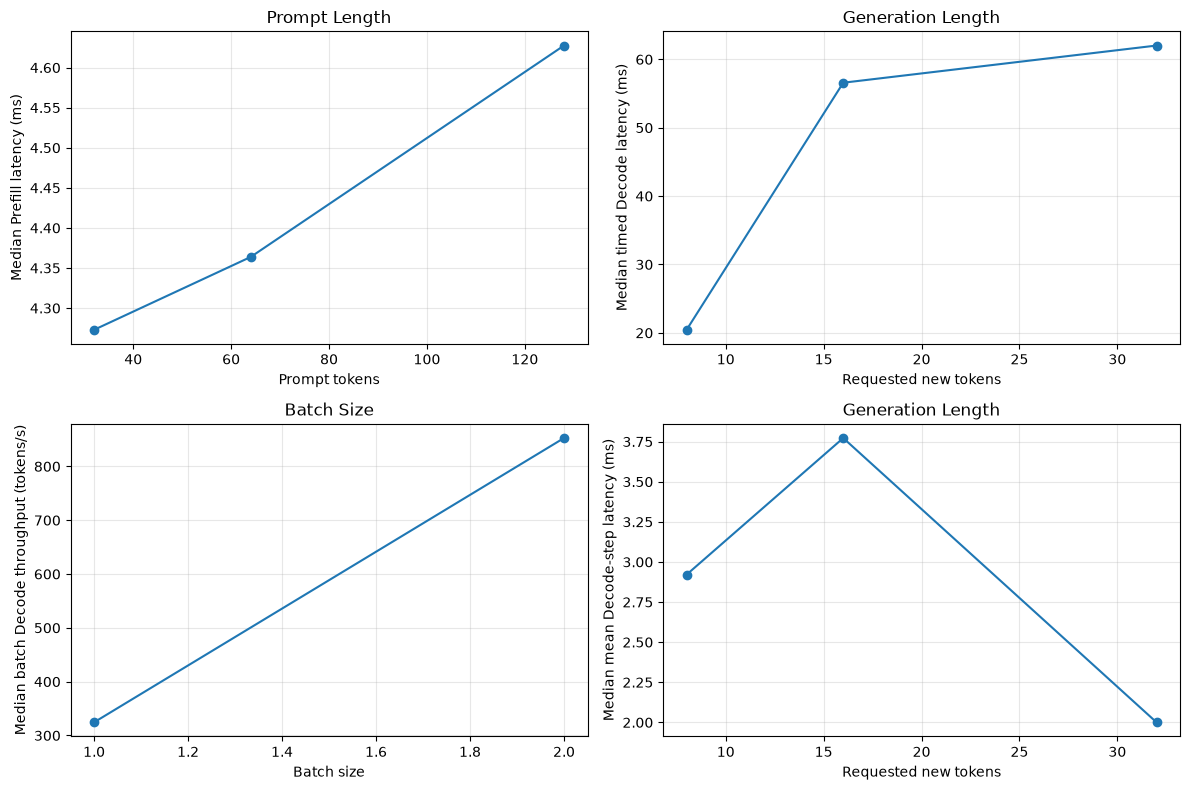

In [5]:
def valid_sweep(experiment):
    data = summary_df[(summary_df.experiment == experiment) & (summary_df.runs_ok > 0)].copy()
    if data.empty:
        print(f"No successful rows for {experiment}")
    return data

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plots = [
    ("prompt_length", "prompt_tokens", "prefill_latency_s_median", 1000,
     "Prompt tokens", "Median Prefill latency (ms)"),
    ("generation_length", "max_new_tokens", "decode_latency_s_median", 1000,
     "Requested new tokens", "Median timed Decode latency (ms)"),
    ("batch_size", "batch_size", "decode_tokens_per_s_median", 1,
     "Batch size", "Median batch Decode throughput (tokens/s)"),
    ("generation_length", "max_new_tokens", "decode_step_latency_mean_s_median", 1000,
     "Requested new tokens", "Median mean Decode-step latency (ms)"),
]
for ax, (experiment, x, y, factor, xlabel, ylabel) in zip(axes.flat, plots):
    data = valid_sweep(experiment).sort_values(x)
    if not data.empty:
        ax.plot(data[x], data[y] * factor, marker="o")
    mixed = bool(comparison_issues(data, x)) if len(data) else False
    title = experiment.replace("_", " ").title() + (" (mixed controls)" if mixed else "")
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.grid(alpha=.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "workload_plots.png", dpi=150)
plt.show()

## Operator rankings and comparison

Plots use the first `PROFILE_WORKLOADS` entry. Rank `aten::` and `prim::` operators by **self CPU time summed across their input-shape groups**, which excludes nested operator time. Total CPU time is inclusive and overlaps across operators; never sum it as a latency estimate. CUDA self device time appears only if CUDA profiler activity succeeds. The profiler itself adds overhead, so compare operator mix, not these times directly with wall-clock benchmark latency.

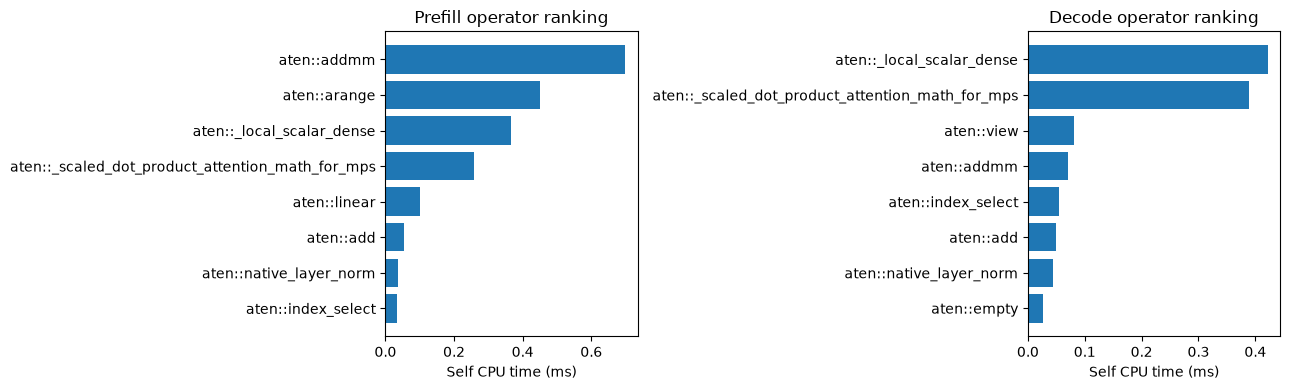

,workload,prefill_latency_s_median,decode_latency_s_median,decode_tokens_per_s_median,end_to_end_tokens_per_s_median
0,prompt_length_p32_n8_b1,0.004273,0.017143,408.338839,366.298286
1,prompt_length_p64_n8_b1,0.004364,0.015718,445.345798,407.285297
2,prompt_length_p128_n8_b1,0.004628,0.015715,445.422453,392.732776
3,generation_length_p64_n8_b1,0.004775,0.020447,342.341531,314.210163
4,generation_length_p64_n16_b1,0.005916,0.056585,265.089294,230.943552
5,generation_length_p64_n32_b1,0.004007,0.062021,499.827359,484.637389
6,batch_size_p64_n8_b1,0.004656,0.021572,324.499725,291.898894
7,batch_size_p64_n8_b2,0.003989,0.016418,852.724751,784.047881


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, phase in zip(axes, ("prefill", "decode")):
    workload_name = PROFILE_WORKLOADS[0].name
    top = rank_operators(operator_df, workload_name, phase).head(8).sort_values("self_cpu_time_us")
    if not top.empty:
        ax.barh(top.operator, top.self_cpu_time_us / 1000)
    ax.set(xlabel="Self CPU time (ms)", title=f"{phase.title()} operator ranking")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "operator_rankings.png", dpi=150, bbox_inches="tight")
plt.show()

comparison = summary_df.loc[summary_df.runs_ok > 0,
    ["workload", "prefill_latency_s_median", "decode_latency_s_median",
     "decode_tokens_per_s_median", "end_to_end_tokens_per_s_median"]]
display(comparison)

## Save metadata and evidence report

`report.md` labels direct measurements **Observed**, plausible reading **Interpretation**, and ideas needing more evidence **Unverified hypothesis**. No bandwidth, cache, or hardware-stall diagnosis is made here.

In [7]:
run_metadata = metadata(MODEL_NAME, tokenizer, DEVICE, SEED, WORKLOADS,
    PROFILE_WORKLOADS, WARMUP, REPEATS, DECODE_CONTEXT_STEPS, profile_runs, model=model)
run_metadata["run_id"] = RUN_ID
run_metadata["workload_plan"] = workload_plan_df.to_dict(orient="records")
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(run_metadata, indent=2, default=str), encoding="utf-8")
report = build_report(run_metadata, summary_df, stability_df, operator_df, profile_runs)
(OUTPUT_DIR / "report.md").write_text(report, encoding="utf-8")
print("Saved Level 2 artifacts in", OUTPUT_DIR.resolve())
print(report)

Saved Level 2 artifacts in /Users/Huy/VSCode/DataProccessing/profiling_framework_mvp/notebooks/results/notebook_level2
# Level 2 profiling report

Run: 2026-10-12T18:06:31.306169+00:00
Model: `sshleifer/tiny-gpt2`; device: `mps`; PyTorch: `2.14.1`.

## Method

1 warm-up and 3 measured runs per workload. 
Tokenization, model loading, and profiling are outside benchmark timing. Prefill includes the first generated token's model forward. 
Decode times the remaining cached one-token model forwards. Batch throughput counts tokens across all sequences.
Only traces listed in this report belong to this result set; older trace files may remain on disk.

## Workloads and observed measurements

- **Observed:** `prompt_length_p32_n8_b1` (ok; 3/3 successful, 0 failed, 0 skipped, 0 unsupported): median prefill 4.273 ms; decode 17.143 ms; decode throughput 408.339 tokens/s; total throughput 366.298 tokens/s.
- **Observed:** `prompt_length_p64_n8_b1` (ok; 3/3 successful, 0 failed, 0 skipped, 0 unsuppo

## Limits

The tiny model validates the workflow but does not represent a production LLM. Python overhead, backend dispatch, and synchronization affect wall time. Profiler CPU operator time is not device execution time. MPS operator-level device timing may be unavailable. A single cached Decode forward cannot describe every context length. Run more repeats and longer workloads for stable research conclusions. Level 3 hardware counters are deferred.

`model_revision` is null if Transformers does not expose a resolved commit hash. That limits cross-run model identity claims, even when the model ID matches. Standard deviation uses the sample formula (`ddof=1`); p90 uses linear interpolation. Both are unavailable when insufficient valid values exist. CPU operator self time excludes nested operator work. Total CPU time is inclusive, and totals across operators overlap. CUDA device timing is only populated when the CUDA profiler activity succeeds; device call counts remain unavailable.